# Análisis del discurso, eje 1: designaciones y calificativos en las fuentes primarias

**Corpus:** los 7 volúmenes de *La Rebelión de Túpac Amaru II* (Colección Documental, Congreso del Perú), **solo fuentes primarias**
(`rol == "fuente_primaria"`, columna `texto_fuente`): sin paratexto editorial, sin artículos académicos y sin notas al pie del editor.
**Pregunta:** ¿con qué palabras se nombra el hecho y a su protagonista, y cambia eso a lo largo de los volúmenes?
**Método:** frecuencias relativas, términos que acompañan al nombre de Túpac Amaru, colocaciones (log-likelihood de Dunning) y
concordancias. No hay modelos entrenados: cada cifra se puede rastrear a su página con `kwic()`.

La lógica vive en [`discurso.py`](discurso.py); aquí se usa y se interpreta.

## 1. Preparación

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import discurso

OUT = Path("data") / "discurso"
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "font.size": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
AZUL, NARANJA, VERDE, ROJO, GRIS = "#2a6fb0", "#d97a1f", "#3a8f5c", "#b03a48", "#777777"

prim = discurso.cargar()
resumen = (prim.assign(palabras=prim["match"].str.split().str.len())
               .groupby("volumen").agg(paginas=("pagina", "size"), palabras=("palabras", "sum")))
resumen

,paginas,palabras
volumen,,
1,703,287666
2,1000,322667
3,865,335774
4,919,335126
5,597,257706
6,878,280383
7,1102,343698


`cargar()` hace tres cosas que importan para los conteos: une las palabras cortadas por guion de fin de línea (*«rei- no»* → *reino*),
**quita los encabezados corridos** que el OCR repite en cada página y busca sin tildes. Sin quitar encabezados como
*«Causas criminales seguidas contra los rebeldes»*, "rebelde" aparecía inflado en los vols. 6 y 7.

## 2. Léxico de designaciones

In [2]:
for categoria, terminos in discurso.LEXICO.items():
    print(f"{categoria}: " + ", ".join(terminos))

rebeldía: rebelde, rebelión, sublevado/sublevación, insurgente, alboroto/tumulto, sedición/conmoción, levantamiento, revolución
criminalización: traidor, tirano, infame, malvado/facineroso, insolente, reo
autoridad y linaje: inca, cacique, caudillo, gobernador, don
adscripción étnica: indio, natural, mestizo, español


Cuatro familias: cómo se nombra la **rebeldía**, cómo se **criminaliza**, qué marca **autoridad y linaje** y qué **adscripción étnica** se usa.
Las grafías antiguas (*ynga*, *inga*, *Tupa*, *Amaro*) están agrupadas. Es un léxico de partida, pensado para ampliarse.

## 3. Frecuencia por volumen

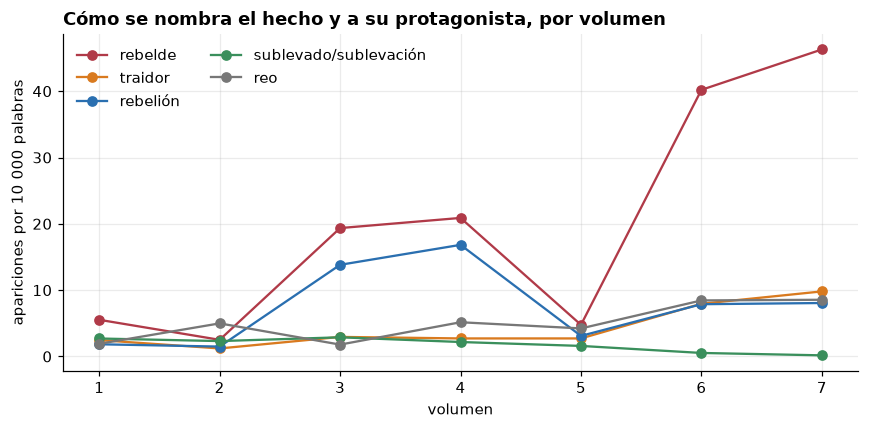

In [3]:
freq = discurso.frecuencia_por_volumen(prim)
freq.to_csv(OUT / "frecuencia_por_volumen.csv", index=False)

clave = {"rebelde": ROJO, "traidor": NARANJA, "rebelión": AZUL, "sublevado/sublevación": VERDE, "reo": GRIS}
fig, ax = plt.subplots(figsize=(8, 4))
for t, color in clave.items():
    s = freq[freq["termino"] == t].set_index("volumen")["por_10k"]
    ax.plot(s.index, s.values, marker="o", color=color, label=t)
ax.set_xlabel("volumen"); ax.set_ylabel("apariciones por 10 000 palabras")
ax.set_title("Cómo se nombra el hecho y a su protagonista, por volumen")
ax.legend(frameon=False, ncol=2)
fig.tight_layout(); fig.savefig(OUT / "01_frecuencia_clave.png"); plt.show()

In [4]:
(freq.pivot_table(index=["categoria", "termino"], columns="volumen", values="por_10k")
     .style.format("{:.1f}").background_gradient(axis=1, cmap="Blues"))

**Lectura.** *Rebelde* salta de ~5 por 10 000 palabras (vols. 1–2) a ~40–46 (vols. 6–7) y *traidor* pasa de ~2,5 a ~8–10:
el epíteto se fija en los volúmenes de causas criminales. *Sublevación* hace el camino inverso (de ~2,7 a ~0,2): el vocabulario
deja de nombrar el hecho para calificar a la persona. *Revolución* casi no aparece (<0,5 en todos los volúmenes), por lo que
**"rebelión" es la designación dominante** en las fuentes de la época.

**Cuidado:** los vols. 6–7 son *causas criminales*; parte del salto refleja el género documental (un proceso judicial califica al reo),
no una evolución del discurso. Esto se aborda en el eje 2, segmentando por tipo de documento.

## 4. Lo que se dice junto al nombre de Túpac Amaru

Menciones del nombre por volumen: {1: 195, 2: 447, 3: 980, 4: 987, 5: 556, 6: 1452, 7: 1763}


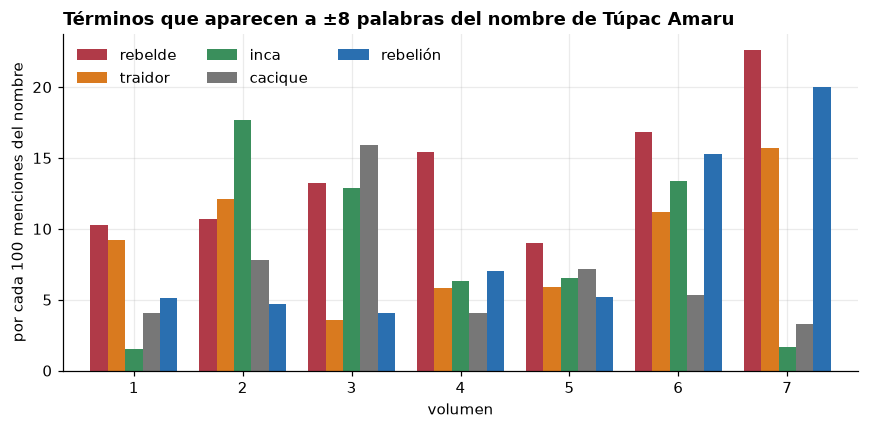

In [5]:
rot = discurso.rotulos_actor(prim)
rot.to_csv(OUT / "rotulos_actor.csv", index=False)

menciones = rot.groupby("volumen")["menciones_actor"].first()
print("Menciones del nombre por volumen:", menciones.to_dict())

terminos = ["rebelde", "traidor", "inca", "cacique", "rebelión"]
tabla = (rot[rot["termino"].isin(terminos)]
         .pivot_table(index="volumen", columns="termino", values="por_100_menciones")[terminos].fillna(0))
ax = tabla.plot(kind="bar", figsize=(8, 4), color=[ROJO, NARANJA, VERDE, GRIS, AZUL], width=0.8)
ax.set_xlabel("volumen"); ax.set_ylabel("por cada 100 menciones del nombre")
ax.set_title("Términos que aparecen a ±8 palabras del nombre de Túpac Amaru")
ax.legend(frameon=False, ncol=3); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(OUT / "02_rotulos_actor.png"); plt.show()

**Lectura.** Dos registros conviven: uno **de linaje** (*inca*, *cacique*), fuerte en los vols. 2–3 y 6, y uno **de condena** (*rebelde*,
*traidor*), que domina el vol. 7. El nombre propio queda así cargado de títulos contrapuestos: el del *descendiente* de los incas y el
del *traidor* a la corona.

## 5. Colocaciones

In [6]:
objetivos = {"rebelde": r"rebelde[s]?", "traidor": r"traidor(?:es)?", "inca": r"(?:inca|inga|ynga)", "cacique": r"cacique[s]?"}
cols = {n: discurso.colocaciones(prim, p, ventana=5, min_n=5, top=15) for n, p in objetivos.items()}
for n, c in cols.items():
    c.to_csv(OUT / f"colocaciones_{n}.csv", index=False)
pd.concat({n: c["palabra"] for n, c in cols.items()}, axis=1)

,rebelde,traidor,inca,cacique
0,amaro,amaro,amaro,pueblo
1,tupa,vil,roca,tungasuca
2,gabriel,ejecutada,gabriel,amaro
3,mujer,tupa,tupa,tupa
4,jose,gabriel,tupac,jose
5,tupac,jose,jose,chinchero
6,dicho,tupac,don,alcaldes
7,auxiliaba,rebelion,felipe,surimana
8,forzado,apostatas,amaru,acomayo
9,servido,cacique,yupanqui,vil


Palabras que acompañan a cada término a ±5 palabras, ordenadas por log-likelihood frente al corpus (solo atracciones, mínimo 5 co-ocurrencias).

- **traidor** se asocia con *vil*, *infame*, *inicuo*, *apóstatas* y *corona*: la traición se formula frente al rey y a la religión.
- **inca** se asocia con *descendiente*, *Manco*, *Yupanqui*, *Felipe*: la genealogía es el argumento.
- **cacique** se asocia con topónimos (*Tungasuca*, *Chinchero*, *Surimana*, *Anta*, *Tinta*): es un cargo local antes que un título simbólico.
- **rebelde** aparece sobre todo junto al nombre y a verbos de auxilio (*auxiliaba*, *servido*, *forzado*): en los procesos, el rebelde es el
  punto de referencia para medir la culpa de los demás.

## 6. Concordancias

Las cifras anteriores se pueden auditar leyendo el contexto. `kwic()` devuelve volumen, página, contexto y enlace a la página original.

In [7]:
def ver(patron, n=8, volumen=None, ancho=70):
    k = discurso.kwic(prim, patron, ancho=ancho, volumen=volumen)
    print(f"{len(k):,} ocurrencias" + (f" en el vol. {volumen}" if volumen else ""))
    for r in k.sample(min(n, len(k)), random_state=1).sort_values(["volumen", "pagina"]).itertuples():
        print(f"vol. {r.volumen} p. {r.pagina:>4} | {r.izquierda:>{ancho}}  [{r.termino}]  {r.derecha}")

ver(r"rebelde[s]?", volumen=7)

1,591 ocurrencias en el vol. 7
vol. 7 p.  456 | e la fatal opresión en que nos veíamos bajo del insoportable yugo del   [rebelde]   josé gabriel tupa amaro, exclamé pidiéndoles me consolasen y diesen a
vol. 7 p.  553 | ervido de su voluntad al rebelde, dijo que hacía lo que le mandaba el   [rebelde]   túpac amaro por miedo que le tenía, y responde. preguntado si tenía m
vol. 7 p.  730 |  y que don juan antonio figueroa, le hizo el bien de persuadir así al   [rebelde]   y a su mujer, como a toda la gentulla, que sólo le faltaba al testigo
vol. 7 p.  770 | as y sólo sabe que habiéndose echado bando de parte del rey contra el   [rebelde]  , haciendo notoria su traición, persiguió éste al linaje de los castel
vol. 7 p.  791 | erte; mas teniendo presente fue compelido para la concurrencia por el   [rebelde]   que asistió con displicencia a los /.21v mandados del traidor, como l
vol. 7 p.  875 |  mas tribiales. 4° item si les consta, que micaela bastidas muje1 del   [rebelde]   tupa amaro, e

In [8]:
ver(r"traidor(?:es)?")

930 ocurrencias
vol. 1 p.  501 | rechos de su jurisdicción real; y ya delatando, con celo heroico, los   [traidores]   a la majestad y al estado que contienen estas provincias. que al paso
vol. 3 p.  504 | ultar a nuestra reflexión que, así como se ha atrevido a manifestarse   [traidor]   a nuestro soberano, se mostrará después también ingrato y rigoroso co
vol. 3 p.  510 | nción mándeme usted sin pérdida de tiempo, porque puede retroceder el   [traidor]   contra mí, porque dice mi hijo que hicieron cuenta de más de doce mil
vol. 3 p.  794 | de marzo de 1781. las medidas tomadas para prender la persona del vil   [traidor]   josé gabriel tupac-amaru, y sus indignos auxiliadores, van saliendo m
vol. 4 p.  187 |  en todos los asuntos de la rebelión intentada y executada por el vil   [traidor]   josef gabriel tupa amaro. en la ciudad del cuzco á catorce de julio d
vol. 6 p.  277 | practicadas sobre la sublevación de prisiones que ha intentado el vil   [traidor]   tupa amaro, y palabras que

In [9]:
ver(r"(?:inca|inga|ynga)", volumen=2)

108 ocurrencias en el vol. 2
vol. 2 p.   66 | agdalena ocllo, su mujer, fueron sus padres, y de la descendencia del   [inca]   túpac amaro, señor natural que fué de estos reinos, y que así también
vol. 2 p.   66 | ue de surimana, y que le oyó (decir) a éste que don blas túpac amaro,   [inca]   principal, y doña magdalena ocllo, su mujer, fueron sus padres, y de 
vol. 2 p.   83 | e información que ésta dió, consta haber sido hija natural del último   [inca]   don felipe túpac amaro, y hasta ahora no se ha probado ni se probará 
vol. 2 p.   84 | sta ahora no ha probado, y entonces podrá ser descendiente del último   [inca]   del perú, como lo soy yo. ultimamente la parte contraria no ha tenido
vol. 2 p.  106 | viajar a españa para que lo represente en sus alegatos de su herencia   [inca]   poder para españa. don josef tupac amaro al dr. dn. jph. antonio garc
vol. 2 p.  107 | elchor aiesta, presentes. (fdo.) jph. gbl. thupa amaro y condorcanqui   [inga]   - juan antonio roxas - pedro manu

Al leerlas se ve el uso fijo *«el rebelde + nombre»* en los procesos (vol. 7), la fórmula *«el vil traidor + nombre»* en los
encabezados de autos (vols. 3, 4, 6, 7) y, en el vol. 2, *«inca»* como **prueba de genealogía** en el pleito por la herencia
(*«descendiente del último inca»*) y como parte de firmas (*«Thupa Amaru y Condorcanqui, Inga»*). Es decir, el mismo término funciona
como título propio en un documento y como dato probatorio en otro. Distinguir quién nombra y con qué fin es lo que busca el eje 2.

## 7. Conclusiones provisionales y límites

1. En las fuentes primarias del corpus **"rebelión/rebelde" domina sobre "revolución"** y el vocabulario de condena (*rebelde*, *traidor*)
   se concentra en los volúmenes judiciales.
2. El nombre de Túpac Amaru convive con **dos registros opuestos**: linaje (*inca*, *cacique*) y condena (*rebelde*, *traidor*).
3. **Sesgo de selección:** cada volumen reúne un género distinto (informes, causas, defensas). Comparar volúmenes mezcla evolución del
   discurso con diferencias de género documental.
4. **Voz:** el recuento no distingue quién habla. *Inca* en boca de Túpac Amaru y *rebelde* en boca de un fiscal son enunciados distintos.
5. **OCR y ortografía:** el texto del siglo XVIII tiene variantes (*Tupa/Tupac*, *Amaro/Amaru*) y errores. El léxico cubre las más
   frecuentes, no todas.

**Siguiente paso (eje 2):** segmentar los volúmenes por tipo de documento y voz enunciadora (carta, bando, auto, declaración) y repetir
este análisis dentro de cada grupo.